# AI Impact Mini-Project — Chapter 2 (Complete Notebook)
**Data Cleaning → Preprocessing → EDA with Graphs → Statistical Analysis → Model Development**

Team: Avismyi · Aadhya · Aishwarya  |  Dataset: 138 survey responses × 11 columns

| Section | Content | Owner (per work manual) |
|---|---|---|
| 1–2 | Dataset understanding + cleaning | Avismyi |
| 4–5 | Preprocessing, statistics, feature selection | Aadhya |
| 3 | Graphical analysis (EDA) | Aishwarya |
| 6 | Model development (added) | Team |

Run top-to-bottom. All figures are saved to `graphs/` and tables to `tables/`.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_score, GridSearchCV)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
os.makedirs("graphs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
os.makedirs("data", exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"graphs/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Libraries loaded.")

Libraries loaded.


## 1. Dataset Understanding (2.1)
Load the **untouched** raw CSV. If you are in Google Colab, upload `ai_impact_survey_raw.csv` into a `data/` folder first (or run the upload cell below).

In [2]:
RAW_PATH = "data/ai_impact_survey_raw.csv"
if not os.path.exists(RAW_PATH):
    try:                                   # Google Colab fallback: upload the CSV manually
        from google.colab import files
        up = files.upload()
        RAW_PATH = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError("Put the raw CSV at data/ai_impact_survey_raw.csv")

raw = pd.read_csv(RAW_PATH)
print("Shape:", raw.shape)
print("\nOriginal column names:")
for c in raw.columns: print("  -", c)
print("\nData types:\n", raw.dtypes.value_counts())
raw.head()

Shape: (138, 11)

Original column names:
  - Timestamp
  - 1.How familiar are you with Artificial Intelligence 
  - 2.How frequently do you use AI tools such as ChatGPT, Gemini, Copilot, etc.?
  - 3. What do you think is the biggest positive impact of AI?
  - 4. What do you think is the biggest negative impact of AI?
  - 5. How has AI affected your productivity?
  - 6. Do you think AI makes education better or creates more problems for students?
  - 7. Which statement best describes your view of AI?
  - 8. If you could choose only ONE, which would you prefer?
  - 9. How concerned are you about your personal data being used by AI systems?
  - 10.Overall how do you think it will affect our future?

Data types:
 str    11
Name: count, dtype: int64


,Timestamp,1.How familiar are you with Artificial Intelligence,"2.How frequently do you use AI tools such as ChatGPT, Gemini, Copilot, etc.?",3. What do you think is the biggest positive impact of AI?,4. What do you think is the biggest negative impact of AI?,5. How has AI affected your productivity?,6. Do you think AI makes education better or creates more problems for students?,7. Which statement best describes your view of AI?,"8. If you could choose only ONE, which would you prefer?",9. How concerned are you about your personal data being used by AI systems?,10.Overall how do you think it will affect our future?
0,8/16/2026 19:03:37,Heard of it,Daily,Makes works and task easier and faster,Misinformation and fake content,Increased significantly,Not sure,Both,A world with AI that makes life easier but increases dependence on technology,Moderately concerned,Depends on humans use
1,8/16/2026 19:07:19,Very familiar,Occasionally,Hepls in solving complex problems,Job displacememt,Increased slowly,Both equally,Both,Less AI more human involvement,Extremely concerned,Depends on humans use
2,8/16/2026 19:08:14,Very familiar,Occasionally,Improves creativity and idea generation,Job displacememt,Increased significantly,Mostly creates problem,Both,A world with AI that makes life easier but increases dependence on technology,Extremely concerned,Mostly negative
3,8/16/2026 19:09:30,Heard of it,Occasionally,Makes works and task easier and faster,Privacy and data security concerns,Increased slowly,Mostly makes education better,Harmful,A world with AI that makes life easier but increases dependence on technology,Moderately concerned,Mostly negative
4,8/16/2026 19:18:02,Very familiar,Daily,Improves creativity and idea generation,Reduced human creativity,Increased significantly,Both equally,Depends on how people use it,Less AI more human involvement,Extremely concerned,Mostly negative


## 2. Data Cleaning (2.2)
Rename the long question headings to short names, check missing values/duplicates, and find text inconsistencies.

In [3]:
df = raw.copy()
df.columns = ["timestamp","familiarity","frequency","positive_impact","negative_impact",
              "productivity","education","view","preference","privacy_concern","future"]

print("Missing cells :", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# strip stray whitespace (safe) and show every distinct answer per question
for c in df.columns[1:]:
    df[c] = df[c].astype(str).str.strip()
for c in df.columns[1:]:
    print(f"\n{c}  ({df[c].nunique()} unique)")
    print(df[c].value_counts().to_string())

Missing cells : 0
Duplicate rows: 0

familiarity  (3 unique)
familiarity
Very familiar    99
Heard of it      34
Not at all        5

frequency  (3 unique)
frequency
Daily           88
Occasionally    47
Never            3

positive_impact  (3 unique)
positive_impact
Makes works and task easier and faster     83
Improves creativity and idea generation    34
Hepls in solving complex problems          21

negative_impact  (4 unique)
negative_impact
Reduced human creativity              60
Job displacememt                      41
Privacy and data security concerns    29
Misinformation and fake content        8

productivity  (4 unique)
productivity
Increased slowly           48
Increased significantly    46
No major change            26
Decreased slighty          18

education  (4 unique)
education
Both equally                     72
Mostly makes education better    45
Mostly creates problem           12
Not sure                          9

view  (4 unique)
view
Depends on how people use 

In [4]:
# Fix only clear spelling / wording slips -- no answer changes meaning, no rows removed
fixes = {
    "positive_impact": {"Hepls in solving complex problems": "Helps in solving complex problems",
                        "Makes works and task easier and faster": "Makes work and tasks easier and faster"},
    "negative_impact": {"Job displacememt": "Job displacement"},
    "productivity":    {"Decreased slighty": "Decreased slightly"},
    "education":       {"Mostly creates problem": "Mostly creates problems"},
    "future":          {"Depends on humans use": "Depends on human use"},
}
for col, mapping in fixes.items():
    df[col] = df[col].replace(mapping)

df["timestamp"] = pd.to_datetime(df["timestamp"], format="%m/%d/%Y %H:%M:%S", errors="coerce")
print("Unparsed timestamps:", int(df["timestamp"].isna().sum()))
print("Shape after cleaning:", df.shape, "| missing:", int(df.isna().sum().sum()),
      "| duplicates:", int(df.duplicated().sum()))
print("Responses collected between", df["timestamp"].min(), "and", df["timestamp"].max())

df.to_csv("data/ai_impact_clean.csv", index=False)
print("Saved -> data/ai_impact_clean.csv")
df.head()

Unparsed timestamps: 0
Shape after cleaning: (138, 11) | missing: 0 | duplicates: 0
Responses collected between 2026-08-16 19:03:37 and 2026-08-18 21:38:33
Saved -> data/ai_impact_clean.csv


,timestamp,familiarity,frequency,positive_impact,negative_impact,productivity,education,view,preference,privacy_concern,future
0,2026-08-16 19:03:37,Heard of it,Daily,Makes work and tasks easier and faster,Misinformation and fake content,Increased significantly,Not sure,Both,A world with AI that makes life easier but increases dependence on technology,Moderately concerned,Depends on human use
1,2026-08-16 19:07:19,Very familiar,Occasionally,Helps in solving complex problems,Job displacement,Increased slowly,Both equally,Both,Less AI more human involvement,Extremely concerned,Depends on human use
2,2026-08-16 19:08:14,Very familiar,Occasionally,Improves creativity and idea generation,Job displacement,Increased significantly,Mostly creates problems,Both,A world with AI that makes life easier but increases dependence on technology,Extremely concerned,Mostly negative
3,2026-08-16 19:09:30,Heard of it,Occasionally,Makes work and tasks easier and faster,Privacy and data security concerns,Increased slowly,Mostly makes education better,Harmful,A world with AI that makes life easier but increases dependence on technology,Moderately concerned,Mostly negative
4,2026-08-16 19:18:02,Very familiar,Daily,Improves creativity and idea generation,Reduced human creativity,Increased significantly,Both equally,Depends on how people use it,Less AI more human involvement,Extremely concerned,Mostly negative


**Interpretation:** The survey has no missing cells and no duplicate rows, so no imputation or row deletion is needed. Cleaning only standardised misspelled labels (e.g. *Job displacememt → Job displacement*). All 138 responses are kept.

## 3. Graphical Analysis / EDA (2.4.2)

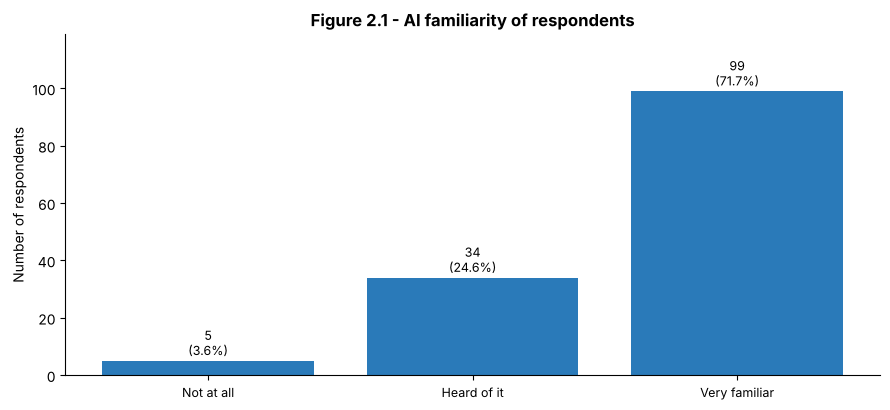

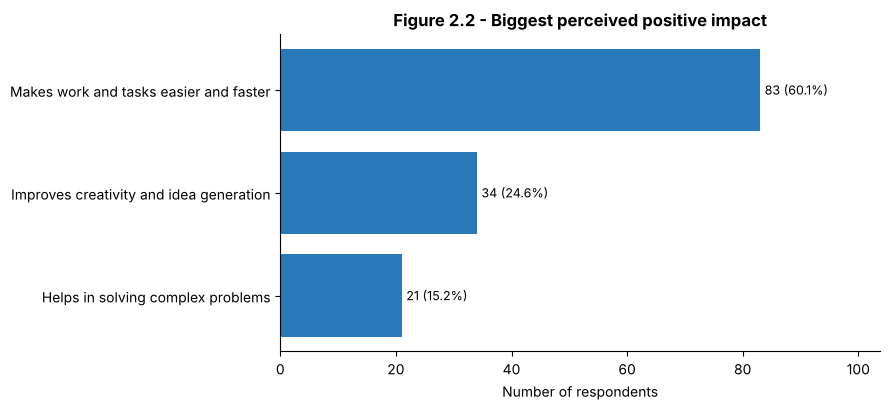

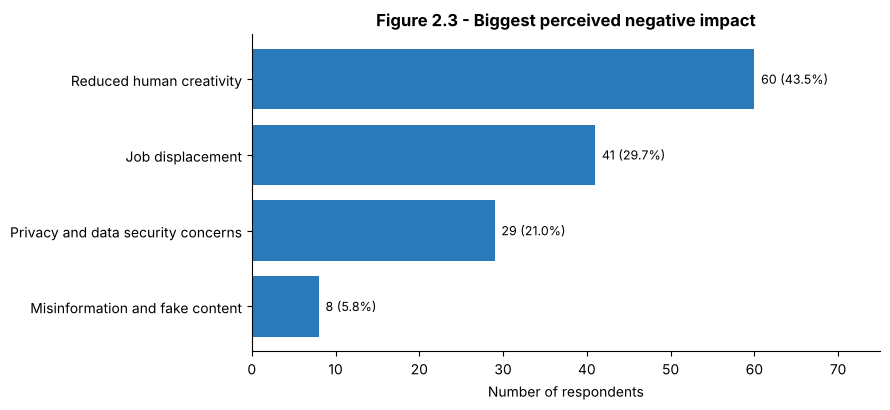

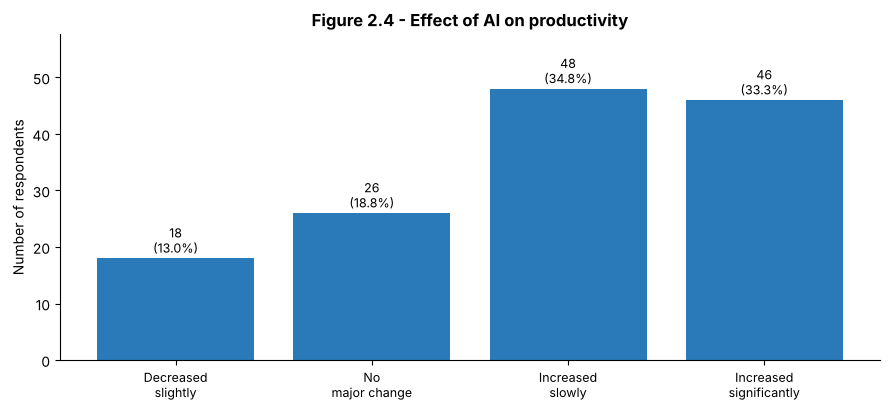

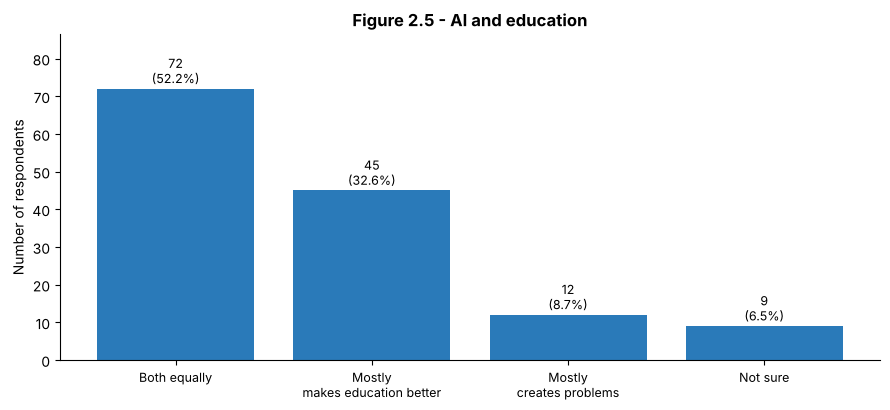

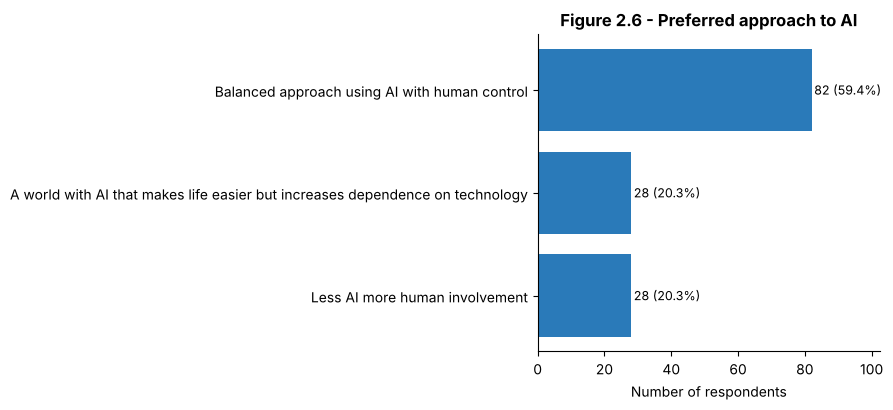

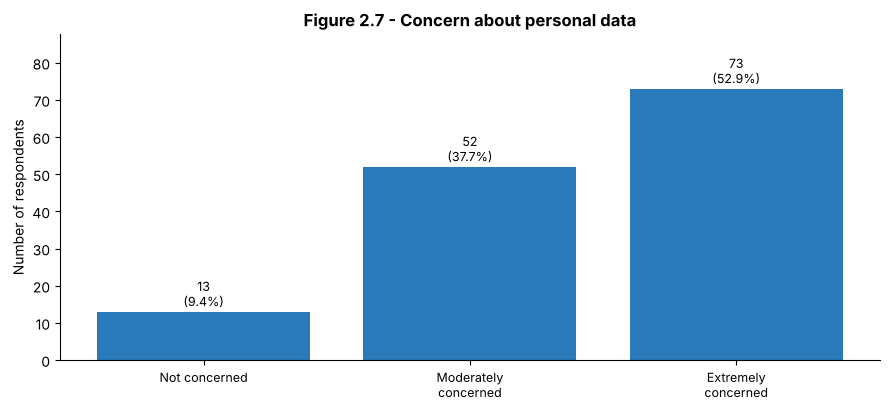

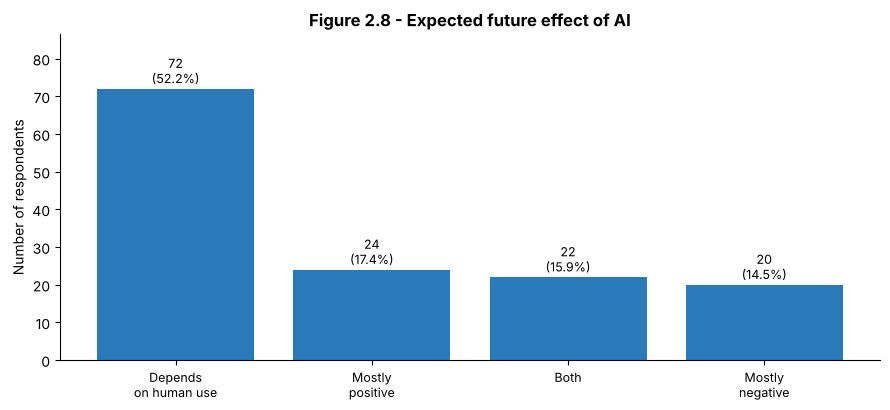

In [5]:
ORD = {
    "familiarity":     ["Not at all", "Heard of it", "Very familiar"],
    "frequency":       ["Never", "Occasionally", "Daily"],
    "productivity":    ["Decreased slightly", "No major change", "Increased slowly", "Increased significantly"],
    "privacy_concern": ["Not concerned", "Moderately concerned", "Extremely concerned"],
}
TITLES = {
    "familiarity": "Figure 2.1 - AI familiarity of respondents",
    "positive_impact": "Figure 2.2 - Biggest perceived positive impact",
    "negative_impact": "Figure 2.3 - Biggest perceived negative impact",
    "productivity": "Figure 2.4 - Effect of AI on productivity",
    "education": "Figure 2.5 - AI and education",
    "preference": "Figure 2.6 - Preferred approach to AI",
    "privacy_concern": "Figure 2.7 - Concern about personal data",
    "future": "Figure 2.8 - Expected future effect of AI",
    "frequency": "Figure 2.9 - Frequency of AI-tool use",
    "view": "Figure 2.10 - Overall view of AI",
}
LONG = ["positive_impact", "negative_impact", "preference"]   # long labels -> horizontal bars

def bar(col):
    order = ORD.get(col, df[col].value_counts().index.tolist())
    counts = df[col].value_counts().reindex(order)
    pct = counts / counts.sum() * 100
    fig, ax = plt.subplots(figsize=(9, 4.2))
    if col in LONG:
        ax.barh(counts.index[::-1], counts.values[::-1], color="#2a7ab9")
        for i, (v, p) in enumerate(zip(counts.values[::-1], pct.values[::-1])):
            ax.text(v + 0.8, i, f"{v} ({p:.1f}%)", va="center", fontsize=9)
        ax.set_xlabel("Number of respondents"); ax.set_xlim(0, counts.max() * 1.25)
    else:
        ax.bar(range(len(counts)), counts.values, color="#2a7ab9")
        ax.set_xticks(range(len(counts)))
        ax.set_xticklabels([l.replace(" ", "\n", 1) if len(l) > 14 else l for l in counts.index], fontsize=9)
        for i, (v, p) in enumerate(zip(counts.values, pct.values)):
            ax.text(i, v + counts.max() * 0.01, f"{v}\n({p:.1f}%)", ha="center", va="bottom", fontsize=9)
        ax.set_ylabel("Number of respondents"); ax.set_ylim(0, counts.max() * 1.2)
    ax.set_title(TITLES[col], fontweight="bold")
    save_fig(f"{TITLES[col].split(' - ')[0].replace('Figure ', 'fig_').replace('.', '_')}_{col}")

for c in ["familiarity", "positive_impact", "negative_impact", "productivity",
          "education", "preference", "privacy_concern", "future"]:
    bar(c)

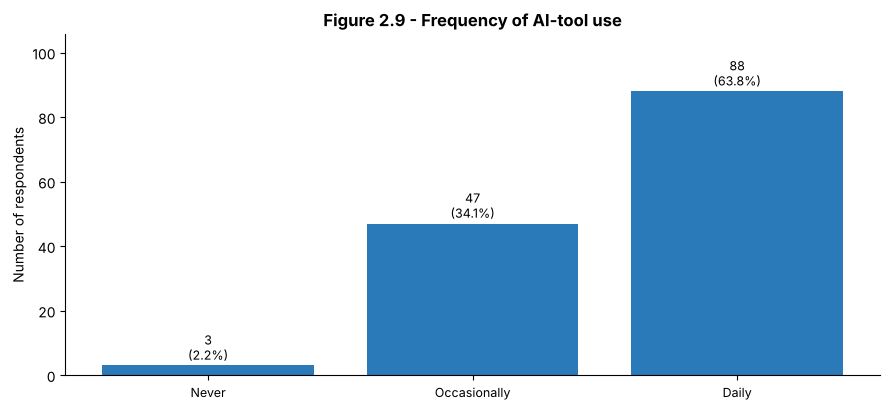

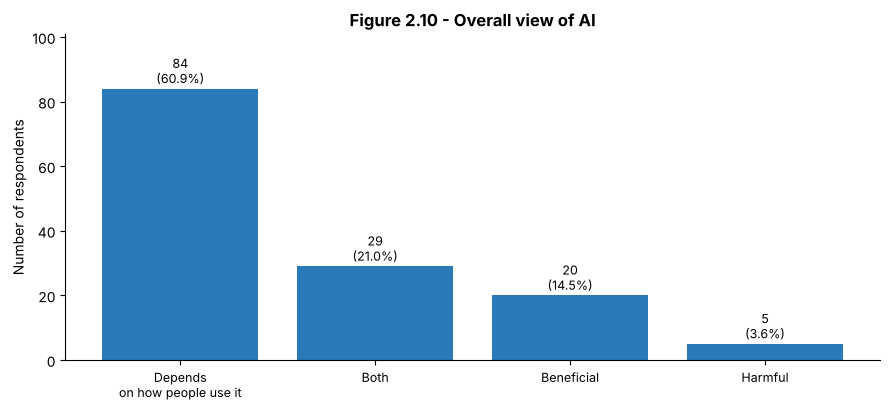

In [6]:
bar("frequency"); bar("view")

**Interpretation (Figures 2.1–2.10):**
- Awareness is high: ~72% are *very familiar* with AI, and ~64% use AI tools *daily*.
- Efficiency ("easier and faster", ~60%) is the leading benefit; *reduced human creativity* (~44%) and *job displacement* (~30%) lead the concerns.
- ~68% report productivity gains; ~91% are at least moderately concerned about personal data.
- Respondents prefer a **balanced approach with human control** (~59%), and ~52% say the future impact *depends on human use* — a conditional rather than purely positive/negative view.

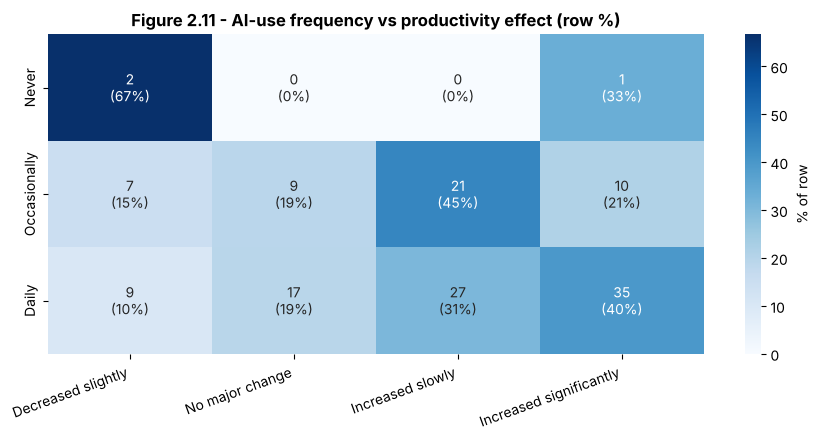

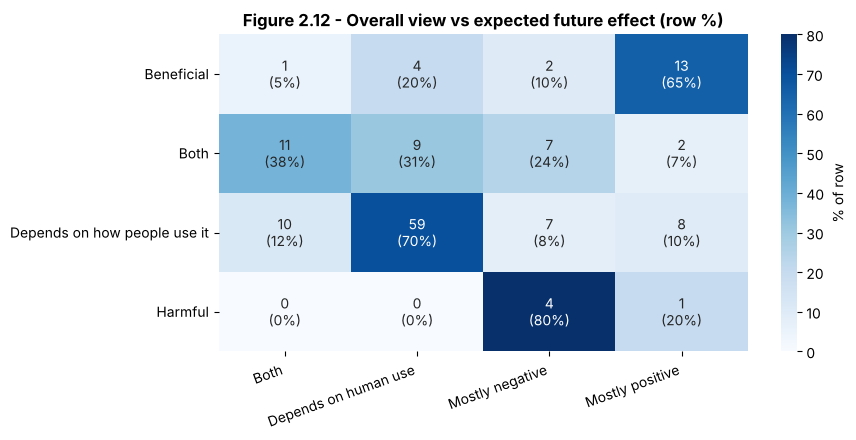

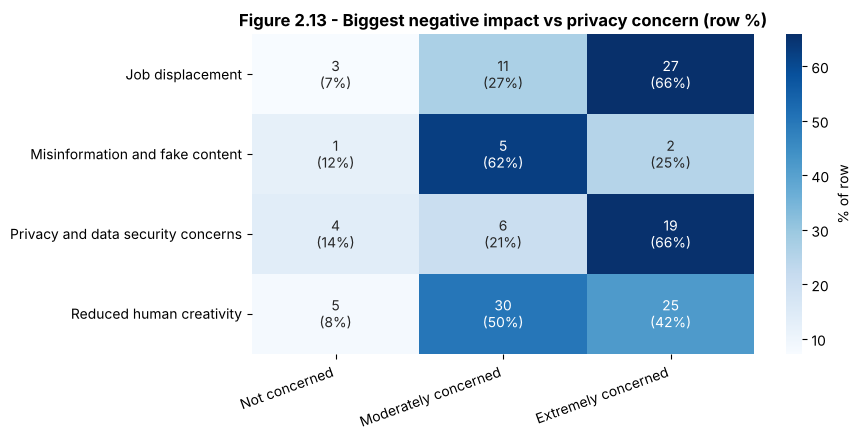

In [7]:
# Relationship plots between categorical questions
def heat_ct(rows, cols, title, name, row_order=None, col_order=None, normalize=True):
    ct = pd.crosstab(df[rows], df[cols])
    if row_order: ct = ct.reindex(row_order)
    if col_order: ct = ct[col_order]
    data = ct.div(ct.sum(axis=1), axis=0) * 100 if normalize else ct
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.heatmap(data, annot=ct.astype(str) + "\n(" + data.round(0).astype(int).astype(str) + "%)" if normalize else True,
                fmt="", cmap="Blues", cbar_kws={"label": "% of row"}, ax=ax)
    ax.set_title(title, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
    plt.xticks(rotation=20, ha="right")
    save_fig(name)

heat_ct("frequency", "productivity", "Figure 2.11 - AI-use frequency vs productivity effect (row %)",
        "fig_2_11_frequency_vs_productivity", ORD["frequency"], ORD["productivity"])
heat_ct("view", "future", "Figure 2.12 - Overall view vs expected future effect (row %)",
        "fig_2_12_view_vs_future")
heat_ct("negative_impact", "privacy_concern", "Figure 2.13 - Biggest negative impact vs privacy concern (row %)",
        "fig_2_13_negative_vs_privacy", None, ORD["privacy_concern"])

**Interpretation:** Daily users are spread across all productivity answers, so frequency alone does not decide the productivity effect. The *view → future* heatmap shows that opinions about AI and expectations of the future are clearly linked, which is why `view` ranks high in feature selection later.

## 4. Data Preprocessing (2.3)
**Encoding:** the four ordered questions are ordinal-encoded; unordered questions are one-hot encoded. Then both normalization (Min-Max) and standardization (Z-score) are demonstrated.

In [8]:
ORD_MAPS = {
    "familiarity":     {"Not at all": 1, "Heard of it": 2, "Very familiar": 3},
    "frequency":       {"Never": 1, "Occasionally": 2, "Daily": 3},
    "productivity":    {"Decreased slightly": 1, "No major change": 2, "Increased slowly": 3, "Increased significantly": 4},
    "privacy_concern": {"Not concerned": 1, "Moderately concerned": 2, "Extremely concerned": 3},
}
for c, m in ORD_MAPS.items():
    df[c + "_enc"] = df[c].map(m)
ENC = [c + "_enc" for c in ORD_MAPS]
assert df[ENC].notna().all().all(), "Unmapped ordinal label found!"

NOMINAL = ["positive_impact", "negative_impact", "education", "view", "preference"]
X_onehot = pd.get_dummies(df[NOMINAL], prefix=NOMINAL, dtype=int)
print("Ordinal columns :", ENC)
print("One-hot columns :", X_onehot.shape[1])
df[ENC].head()

Ordinal columns : ['familiarity_enc', 'frequency_enc', 'productivity_enc', 'privacy_concern_enc']
One-hot columns : 18


,familiarity_enc,frequency_enc,productivity_enc,privacy_concern_enc
0,2,3,4,2
1,3,2,3,3
2,3,2,4,3
3,2,2,3,2
4,3,3,4,3


Min-Max normalization check (expect min 0, max 1):
                      norm_min  norm_max
familiarity_norm           0.0       1.0
frequency_norm             0.0       1.0
productivity_norm          0.0       1.0
privacy_concern_norm       0.0       1.0

Z-score standardization check (expect mean 0, sd 1):
                     std_mean  std_sd
familiarity_std           0.0     1.0
frequency_std            -0.0     1.0
productivity_std          0.0     1.0
privacy_concern_std      -0.0     1.0


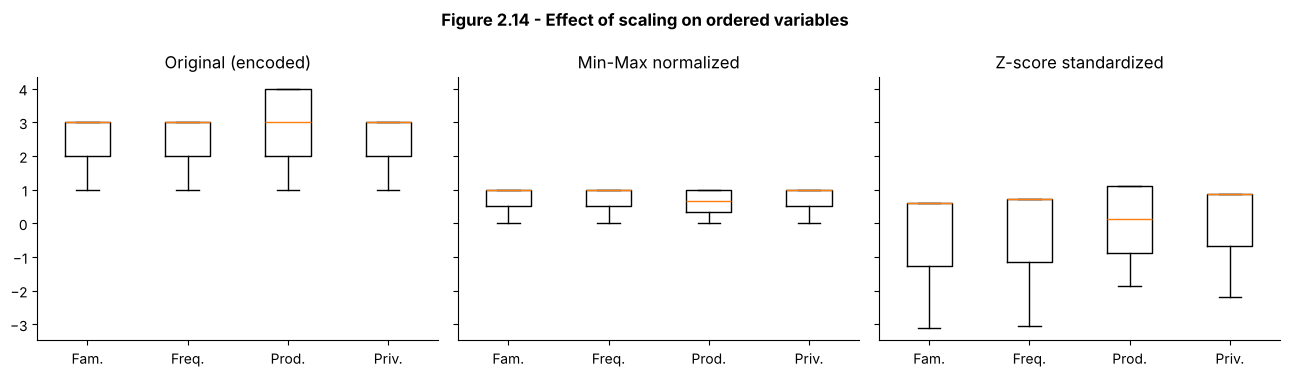

In [9]:
normalized  = pd.DataFrame(MinMaxScaler().fit_transform(df[ENC]), columns=[c.replace("_enc", "_norm") for c in ENC])
standardized = pd.DataFrame(StandardScaler().fit_transform(df[ENC]), columns=[c.replace("_enc", "_std") for c in ENC])

check = pd.DataFrame({
    "norm_min": normalized.min(), "norm_max": normalized.max()}).round(2)
check2 = pd.DataFrame({"std_mean": standardized.mean(), "std_sd": standardized.std(ddof=0)}).round(2)
print("Min-Max normalization check (expect min 0, max 1):"); print(check.to_string())
print("\nZ-score standardization check (expect mean 0, sd 1):"); print(check2.to_string())

# visual before / after
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (data, t) in zip(axes, [(df[ENC], "Original (encoded)"), (normalized, "Min-Max normalized"), (standardized, "Z-score standardized")]):
    ax.boxplot([data[c] for c in data.columns])
    ax.set_xticklabels(["Fam.", "Freq.", "Prod.", "Priv."])
    ax.set_title(t)
fig.suptitle("Figure 2.14 - Effect of scaling on ordered variables", fontweight="bold")
save_fig("fig_2_14_scaling_comparison")

           variable  Q1  Q3  lower_fence  upper_fence  n_outliers
    familiarity_enc 2.0 3.0          0.5          4.5           0
      frequency_enc 2.0 3.0          0.5          4.5           0
   productivity_enc 2.0 4.0         -1.0          7.0           0
privacy_concern_enc 2.0 3.0          0.5          4.5           0


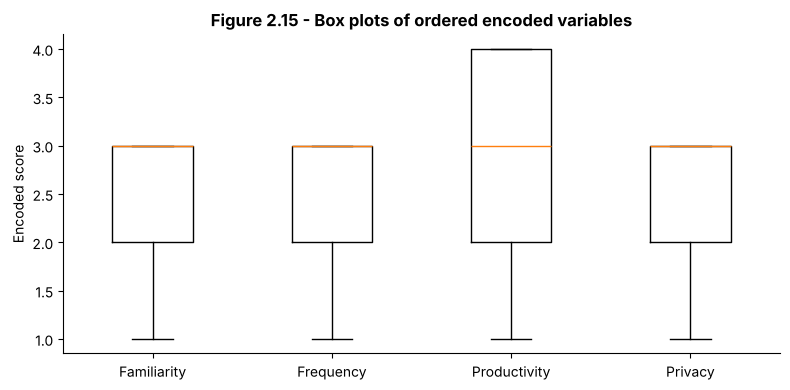

In [10]:
# Outlier check (IQR rule) on ordered encodings, for completeness
rows = []
for c in ENC:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"variable": c, "Q1": q1, "Q3": q3, "lower_fence": lo, "upper_fence": hi,
                 "n_outliers": int(((df[c] < lo) | (df[c] > hi)).sum())})
outliers = pd.DataFrame(rows); outliers.to_csv("tables/outlier_check.csv", index=False)
print(outliers.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([df[c] for c in ENC])
ax.set_xticklabels(["Familiarity", "Frequency", "Productivity", "Privacy"])
ax.set_ylabel("Encoded score"); ax.set_title("Figure 2.15 - Box plots of ordered encoded variables", fontweight="bold")
save_fig("fig_2_15_boxplots")

**Interpretation:** Categories are valid survey answers, not measurements, so no responses are removed even if a box plot marks a point as extreme. Scaling puts all four ordered variables on a comparable range.

## 5. Statistical Analysis (2.4.1) and Feature Selection

                 mean   std  min  median  max  mode
Familiarity      2.68  0.54  1.0     3.0  3.0     3
Frequency        2.62  0.53  1.0     3.0  3.0     3
Productivity     2.88  1.02  1.0     3.0  4.0     3
Privacy concern  2.43  0.66  1.0     3.0  3.0     3
r(frequency, productivity) = 0.173


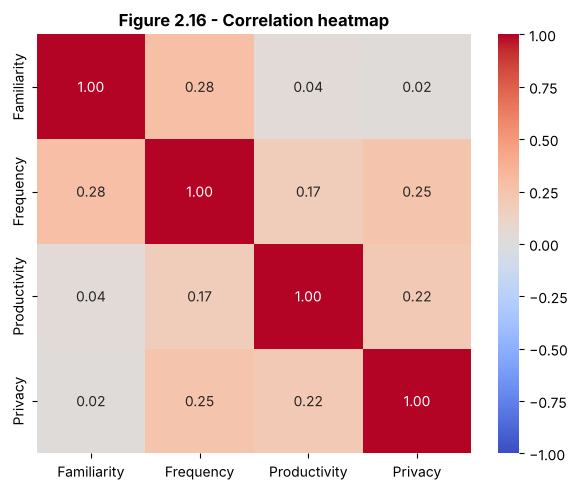

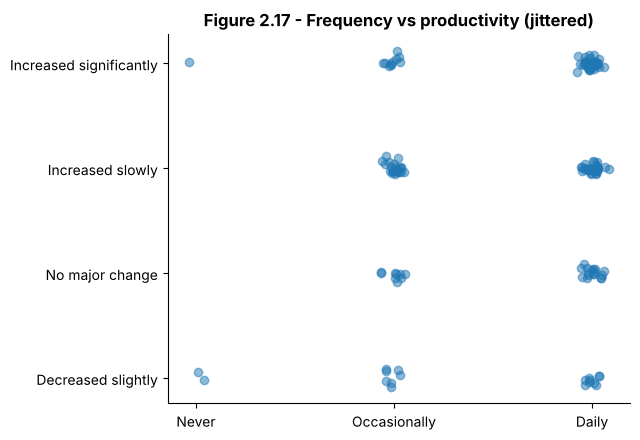

In [11]:
desc = df[ENC].agg(["mean", "std", "min", "median", "max"]).T
desc["mode"] = df[ENC].mode().iloc[0]
desc.index = ["Familiarity", "Frequency", "Productivity", "Privacy concern"]
desc = desc.round(2); desc.to_csv("tables/descriptive_statistics.csv")
print(desc.to_string())

corr = df[ENC].corr().round(3)
corr.index = corr.columns = ["Familiarity", "Frequency", "Productivity", "Privacy"]
corr.to_csv("tables/correlation_matrix.csv")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Figure 2.16 - Correlation heatmap", fontweight="bold")
save_fig("fig_2_16_correlation_heatmap")

# jittered scatter (ordinal data overlaps heavily)
rng = np.random.default_rng(RANDOM_STATE)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(df["frequency_enc"] + rng.normal(0, .04, len(df)), df["productivity_enc"] + rng.normal(0, .04, len(df)), alpha=.5)
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(ORD["frequency"]); ax.set_yticks([1, 2, 3, 4]); ax.set_yticklabels(ORD["productivity"])
ax.set_title("Figure 2.17 - Frequency vs productivity (jittered)", fontweight="bold")
save_fig("fig_2_17_scatter")
print("r(frequency, productivity) =", corr.loc["Frequency", "Productivity"])

**Interpretation:** All correlations are weak (|r| ≤ ~0.28). Familiarity ↔ frequency is the strongest. These are associations, not causes.

                                                                                    feature     MI
0                                                         view_Depends on how people use it  0.109
1                                                                           view_Beneficial  0.105
2  preference_A world with AI that makes life easier but increases dependence on technology  0.072
3                                                                                 view_Both  0.063
4                                                                          productivity_enc  0.060
5                                                         education_Mostly creates problems  0.056
6                                  preference_Balanced approach using AI with human control  0.054
7                                                                              view_Harmful  0.053
8                                                                           familiarity_enc  0.049
9         

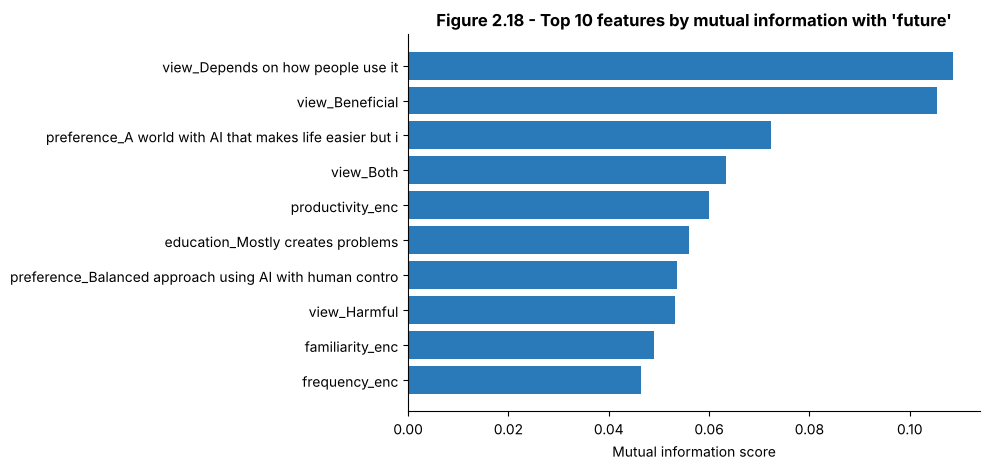

In [12]:
# Feature selection: mutual information vs the 'future' response
X_all = pd.concat([df[ENC], X_onehot], axis=1)
y_codes = df["future"].astype("category").cat.codes
mi = mutual_info_classif(X_all, y_codes, discrete_features=True, random_state=RANDOM_STATE)
ranking = pd.DataFrame({"feature": X_all.columns, "MI": mi}).sort_values("MI", ascending=False).reset_index(drop=True)
ranking.to_csv("tables/mutual_information_ranking.csv", index=False)
print(ranking.head(10).round(3).to_string())

top = ranking.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh([f[:55] for f in top["feature"]], top["MI"], color="#2a7ab9")
ax.set_xlabel("Mutual information score"); ax.set_title("Figure 2.18 - Top 10 features by mutual information with 'future'", fontweight="bold")
save_fig("fig_2_18_mutual_information")

## 6. Model Development
**Goal:** predict the respondent's *expected future effect of AI* (`future`: 4 classes) from the other nine answers.

Design choices:
- Scaling and one-hot encoding live **inside a Pipeline**, so they are fitted only on training folds (no leakage).
- Because the dataset is small (138 rows), models are compared with **repeated stratified 5-fold cross-validation**, and a final 20% stratified hold-out is kept untouched for the last check.
- A **majority-class baseline** is included: 52% of respondents answer *Depends on human use*, so any useful model must beat ~0.52 accuracy.

In [13]:
FEATURES = ["familiarity", "frequency", "productivity", "privacy_concern",
            "positive_impact", "negative_impact", "education", "view", "preference"]
TARGET = "future"

# ordered features -> numeric codes; unordered -> one-hot
X = df[ENC + NOMINAL].copy()
y = df[TARGET]

preprocess = ColumnTransformer([
    ("ord", StandardScaler(), ENC),
    ("nom", OneHotEncoder(handle_unknown="ignore"), NOMINAL),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nClass balance (train):\n", y_train.value_counts(normalize=True).round(3).to_string())

Train: (110, 9) | Test: (28, 9)

Class balance (train):
 future
Depends on human use    0.518
Mostly positive         0.173
Both                    0.164
Mostly negative         0.145


                  model  cv_accuracy  acc_sd  cv_macro_f1  f1_sd
              KNN (k=7)        0.564   0.049        0.362  0.096
    Baseline (majority)        0.518   0.022        0.171  0.005
      Gradient Boosting        0.509   0.090        0.366  0.111
          Random Forest        0.491   0.090        0.394  0.094
              SVM (RBF)        0.461   0.107        0.375  0.101
Decision Tree (depth 4)        0.415   0.112        0.368  0.086
    Logistic Regression        0.379   0.108        0.321  0.085


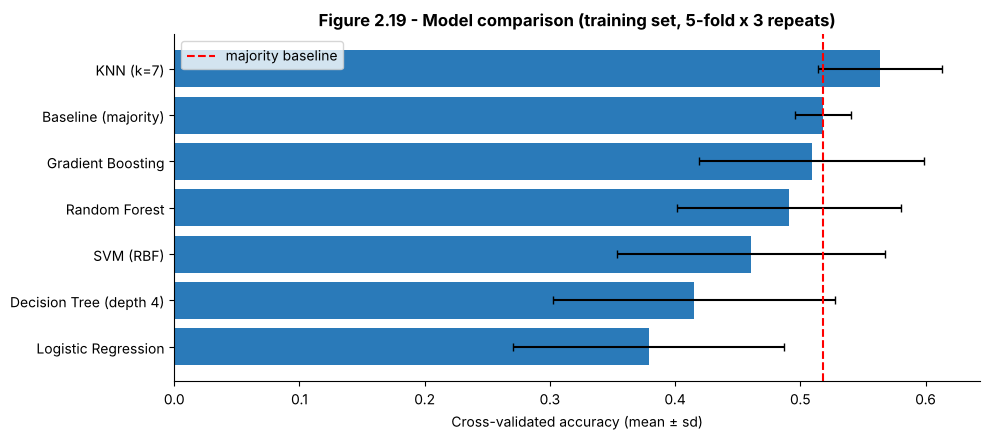

In [14]:
models = {
    "Baseline (majority)":      DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":      LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN (k=7)":                KNeighborsClassifier(n_neighbors=7),
    "Decision Tree (depth 4)":  DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":            RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting":        GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)":                SVC(class_weight="balanced", random_state=RANDOM_STATE),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

rows = []
for name, mdl in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", mdl)])
    acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
    rows.append({"model": name, "cv_accuracy": acc.mean(), "acc_sd": acc.std(), "cv_macro_f1": f1.mean(), "f1_sd": f1.std()})
cv_results = pd.DataFrame(rows).sort_values("cv_accuracy", ascending=False).reset_index(drop=True)
cv_results.round(3).to_csv("tables/model_cv_results.csv", index=False)
print(cv_results.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
s = cv_results.sort_values("cv_accuracy")
ax.barh(s["model"], s["cv_accuracy"], xerr=s["acc_sd"], color="#2a7ab9", capsize=3)
ax.axvline(cv_results.loc[cv_results.model.str.startswith("Baseline"), "cv_accuracy"].iloc[0], color="red", ls="--", label="majority baseline")
ax.set_xlabel("Cross-validated accuracy (mean ± sd)"); ax.legend()
ax.set_title("Figure 2.19 - Model comparison (training set, 5-fold x 3 repeats)", fontweight="bold")
save_fig("fig_2_19_model_comparison")

In [15]:
# Hyper-parameter tuning for the two most promising model families
search_space = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"model__n_estimators": [200, 400], "model__max_depth": [3, 5, None],
                       "model__min_samples_leaf": [1, 3, 5]}),
}
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuned = {}
for name, (mdl, grid) in search_space.items():
    gs = GridSearchCV(Pipeline([("prep", preprocess), ("model", mdl)]), grid,
                      cv=inner_cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name:20s} best macro-F1 (CV) = {gs.best_score_:.3f} | params = {gs.best_params_}")

Logistic Regression  best macro-F1 (CV) = 0.340 | params = {'model__C': 0.1}
Random Forest        best macro-F1 (CV) = 0.387 | params = {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}


              model  test_accuracy  test_macro_f1
Logistic Regression          0.571          0.500
      Random Forest          0.464          0.420
Baseline (majority)          0.536          0.174

Selected model: Random Forest
                      precision    recall  f1-score   support

                Both       0.11      0.25      0.15         4
Depends on human use       0.67      0.53      0.59        15
     Mostly negative       0.50      0.75      0.60         4
     Mostly positive       1.00      0.20      0.33         5

            accuracy                           0.46        28
           macro avg       0.57      0.43      0.42        28
        weighted avg       0.62      0.46      0.48        28



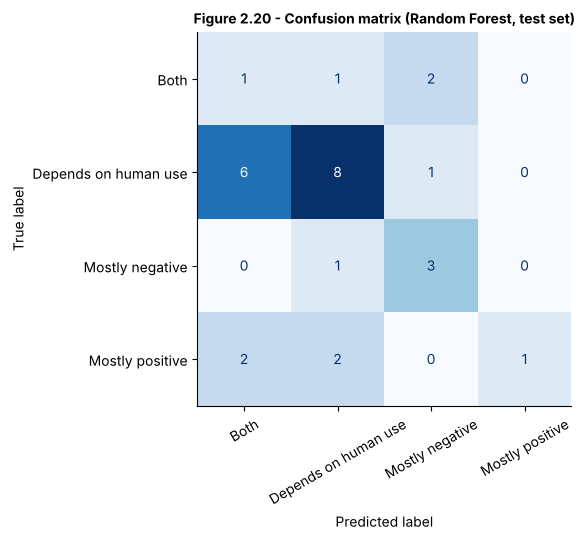

In [16]:
# Final evaluation on the untouched hold-out set
final_rows, preds = [], {}
for name, gs in tuned.items():
    p = gs.predict(X_test); preds[name] = p
    final_rows.append({"model": name, "test_accuracy": accuracy_score(y_test, p), "test_macro_f1": f1_score(y_test, p, average="macro")})
baseline = Pipeline([("prep", preprocess), ("model", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
pb = baseline.predict(X_test)
final_rows.append({"model": "Baseline (majority)", "test_accuracy": accuracy_score(y_test, pb), "test_macro_f1": f1_score(y_test, pb, average="macro")})
final = pd.DataFrame(final_rows).round(3); final.to_csv("tables/final_test_results.csv", index=False)
print(final.to_string(index=False))

# choose by cross-validation score (NOT by test score, to avoid peeking at the hold-out set)
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best = tuned[best_name]
print("\nSelected model:", best_name)
print(classification_report(y_test, preds[best_name], zero_division=0))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, preds[best_name], ax=ax, cmap="Blues", xticks_rotation=30, colorbar=False)
ax.set_title(f"Figure 2.20 - Confusion matrix ({best_name}, test set)", fontweight="bold", fontsize=10)
save_fig("fig_2_20_confusion_matrix")

            feature  importance     sd
               view      0.1748 0.0734
         preference      0.1093 0.0595
          education      0.0799 0.0456
    familiarity_enc      0.0239 0.0294
privacy_concern_enc     -0.0100 0.0329
      frequency_enc     -0.0266 0.0151
   productivity_enc     -0.0463 0.0411
    negative_impact     -0.0480 0.0413
    positive_impact     -0.0550 0.0465


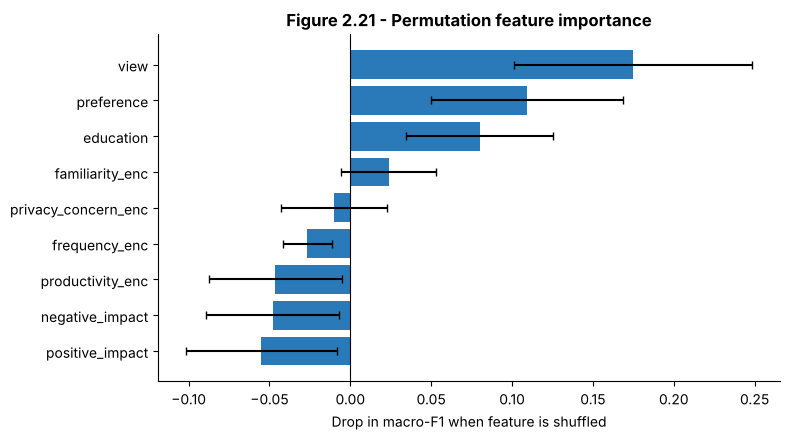

In [17]:
# Which answers drive the predictions? (permutation importance on the hold-out set)
pi = permutation_importance(best, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="f1_macro")
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi.importances_mean, "sd": pi.importances_std})
imp = imp.sort_values("importance", ascending=False).reset_index(drop=True)
imp.round(4).to_csv("tables/permutation_importance.csv", index=False)
print(imp.round(4).to_string(index=False))

s = imp.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(s["feature"], s["importance"], xerr=s["sd"], color="#2a7ab9", capsize=3)
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Drop in macro-F1 when feature is shuffled")
ax.set_title("Figure 2.21 - Permutation feature importance", fontweight="bold")
save_fig("fig_2_21_permutation_importance")

## 7. Model Results, Conclusions and Limitations

**Honest reading of the model results**
- The target (`future`) is dominated by one class (≈52% *Depends on human use*), so a "always predict the majority" baseline already scores ≈0.52–0.54 accuracy.
- In cross-validation the best plain-accuracy model (KNN, ≈0.56) beats the baseline only slightly; the tuned Random Forest was selected because it had the best cross-validated **macro-F1** (≈0.39 vs ≈0.17 for the baseline), i.e. it is the only family that tells the minority classes apart at all.
- On the 28-row hold-out set the Random Forest reaches ≈0.46 accuracy / ≈0.42 macro-F1. Its accuracy is **below** the majority baseline, while macro-F1 is far above it. With only 28 test rows each class has 4–5 examples, so these numbers are very noisy and should not be over-interpreted.
- The model selected for the final test was chosen on cross-validation only; the test set was not used to pick it.
- Permutation importance (and the mutual-information ranking) agree that the respondent's **overall view of AI** (`view`) is the most informative answer for predicting the expected future effect, followed by preferred approach and the education opinion. Several features have ≈0 or negative importance, meaning they add noise rather than signal.

**Overall conclusions**
1. Respondents see AI as useful and productivity-enhancing (≈68% report gains) but are worried about creativity, jobs and privacy (≈91% at least moderately concerned).
2. The dominant theme is *conditional* optimism: ≈59% want a balanced approach with human control and ≈52% say the future depends on how humans use AI.
3. Correlations among the ordered variables are weak (|r| ≤ ≈0.28), so the data support descriptive conclusions far more than predictive or causal ones.
4. Predicting `future` from the other answers works only modestly; the strongest signal is the person's general view of AI.

**Limitations**
- 138 self-reported responses from a convenience sample; results describe this group, not people in general.
- Mostly categorical data and a small test set → model metrics have wide uncertainty (see the ± values in Figure 2.19).
- `view` and `future` are conceptually close questions, so their link is partly expected and is not evidence of causation.
- Ordinal encodings (1,2,3…) assume equal spacing between answer levels, which is an approximation.

**Possible next steps:** collect more responses, merge rare categories (e.g. *Harmful*, n=5), try a binary target (*optimistic vs not*), and report confidence intervals.
